# Convolutional Neural Network NILM

Current issues:
- Scrambled time series.
- Low EACC scores.

Probable Causes
- The predictions and true values are in different row orders.
- The EACC scores are comparing unrelated timesteps.
- Matching on time alone isn't safe. If any time value appears under more than one id, we will match extra rows and arrays may not have the same length. Need to make sure this is not the case.

## Imports 

In [28]:
import os
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.models import load_model
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2' # Hide Warnings

## Settings

In [29]:
dataset_name = 'ampds_cnn_mini'
model_name = 'cnn_nilm_mini'
batch_size = 32
num_epochs = 50

## Directories

In [30]:
notebooks_dir = os.getcwd()
base_dir = os.path.join(notebooks_dir, '..')

processed_data_dir = os.path.join(base_dir, 'processed_data')
results_dir = os.path.join(base_dir, 'results')
os.makedirs(results_dir, exist_ok=True)

model_save_filepath = os.path.join(results_dir, model_name + '.keras')

## Load Data

In [31]:
processed_data_filepath = os.path.join(processed_data_dir, dataset_name + '.npz')
data = np.load(processed_data_filepath)

# Check dataset contents
print(f'Dataset Items: {data.files}')

Dataset Items: ['agg_labels', 'apps_labels', 'electrical_quantities', 'appliance_names', 'agg_data', 'apps_data', 'agg_norm', 'apps_norm', 'apps_min', 'apps_max', 'apps_mean', 'apps_median', 'apps_std', 'apps_on_threshold', 'apps_on_percentrage', 'train_indices', 'val_indices', 'test_indices', 'train_val_test_split', 'T', 'time_resolution', 'time_units', 'window_length', 'stride', 'chunk_size', 'num_chunks']


In [24]:
p_agg_norm = data['agg_norm'][:, 2]
q_agg_norm = data['agg_norm'][:, 3]
p_agg = data['agg_data'][:, 2]

appliance_names = data['appliance_names']
agg_column_names = data['agg_labels']
apps_column_names = data['apps_labels']

p_apps_norm = data['apps_norm'][:, 2:] # Drop 'time' and 'id'
time_id = data['apps_norm'][:, :2]  # Keep 'time' and 'id' to add back later
p_apps = data['apps_data']

train_indices = data['train_indices']
val_indices = data['val_indices']
test_indices = data['test_indices']

window_length = data['window_length']

apps_mean = data['apps_mean']
apps_min = data['apps_min']
apps_max = data['apps_max']

## Sample Generation

We use the sequence-to-point model from [citation]. The model takes a window of time-series data as its input, and predicts the target value at a single timestamp, typically at the window's center. In our case, the input is a window of aggregate data, and the output is the appliance-level data at a single timestamp. 

[citation] recognizes that CNNs are designed for and perform well on two-dimensional data. The method converts the real-power series (P) and reactive-power series (Q) into a two-dimensional P-Q signature matrix. Each element is defined as $S_{xy} = \sqrt{P_x^2 + Q_y^2}$. The first column represents the real power alone, and the first row represents the reactive power alone.

In [17]:
def make_pq_image(p, q):
    
    S = np.zeros((p.size + 1, q.size + 1))
    S[1:, 0] = np.abs(p)
    S[0, 1:] = np.abs(q)
    S[1:, 1:] = np.hypot(p[:, None], q[None, :])
    return S

We apply a 2D fast Fourier transform (FFT) to the P-Q matrix and use its magnitude. The FFT represents the image in terms of spatial frequencies, showing how quickly patterns change across rows and columns. This may reveal appliance characteristics or operating states that are not easy to see in the original image.

In [12]:
def fft(S): return np.abs(np.fft.fft2(S))

Each sample consists of an input image and its corresponding target value. To create each input, we stack the original time-domain P-Q image and its FFT magnitude representation. 

The `create_sample` function takes as inputs the entire aggregate real-power and reactive-power time series, as well as the index of the first sample in the window. It then constructs the window. The `targets` is an array consisting of a single target value for each appliance. The function returns both the input as a pair of the time-domain image and its frequency representation, and the appliance power targets.

In [13]:
def create_sample(frame_start_idx, p_agg_norm, q_agg_norm, p_apps_norm, window_length):
    p = p_agg_norm[frame_start_idx : frame_start_idx + window_length]
    q = q_agg_norm[frame_start_idx : frame_start_idx + window_length]
    center_timestep = frame_start_idx + window_length // 2
    targets = p_apps_norm[center_timestep]
    S = make_pq_image(p, q)
    S_fft = fft(S)
    return (S, S_fft), targets

To create a batch, we simply generate samples for a list of window-start indices. Keras expects each input as a single array (a tensor) with a batch dimension in front. So we turn each list of `len(indices)` arrays into one `(len(indices), window_length + 1, window_length + 1)` array. `[..., np.newaxis]` adds a channel axis, giving a new size of `(len(indices), window_length + 1, window_length + 1, 1)`. This sets us up for `Conv2D`, which requires `(batch, height, width, channels)` (a grayscale image has 1 channel). 

In [14]:
def create_batch(indices, p_agg_norm, q_agg_norm, p_apps_norm, window_length):
    S_list, S_fft_list, targets_list = [], [], []
    for i in indices:
        (S, S_fft), targets = create_sample(i, p_agg_norm, q_agg_norm, p_apps_norm, window_length)
        S_list.append(S)
        S_fft_list.append(S_fft)
        targets_list.append(targets)
    S_batch = np.stack(S_list)[..., np.newaxis]
    S_fft_batch = np.stack(S_fft_list)[..., np.newaxis]
    return (S_batch, S_fft_batch), np.array(targets_list)

## Model 

The method from [citation] uses a two-branch architecture. The time-domain branch takes the P-Q signature as input, while the frequency-domain branch takes the FFT as input. Each branch has its own convolutional filters and produces a feature vector. These vectors are concatenated before passing through the dense and output layers. The number of outputs the model produces depends on the number of appliances. 

In [10]:
def build_branch(input_layer):
        x = layers.Conv2D(30, (10, 10), activation='relu')(input_layer)
        x = layers.Conv2D(30, (8, 8), activation='relu')(x)
        x = layers.Conv2D(40, (6, 6), activation='relu')(x)
        x = layers.Conv2D(50, (5, 5), activation='relu')(x)
        x = layers.Conv2D(50, (5, 5), activation='relu')(x)
        x = layers.Flatten()(x)
        return x

In [11]:
def create_model_architecture(n_appliances):

    # Inputs
    inp_time = layers.Input(shape=(31, 31, 1))
    inp_freq = layers.Input(shape=(31, 31, 1))

    # Branches
    branch_time = build_branch(inp_time)
    branch_freq = build_branch(inp_freq)
    x = layers.Concatenate()([branch_time, branch_freq])

    # Dense + Output Layers
    x = layers.Dense(1024, activation='relu')(x)
    out = layers.Dense(n_appliances)(x)   # one output per appliance

    # Model
    model = models.Model(inputs=[inp_time, inp_freq], outputs=out)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='mse')

    return model

## Model Training

`train_epoch` runs one full pass over the training data and returns the average training loss. It steps through the `train_indices` (window starting indices) one `batch_size` at a time. For each batch, it creates the input and targets. Then `model.train_on_batch()` runs one gradient step on that batch and returns its loss (MSE). The function averages the batch losses and returns that epoch's mean training loss.

In [12]:
def train_epoch(model, p_agg_norm, q_agg_norm, p_apps_norm, train_indices, window_length, batch_size):

    train_loss, num_batches = 0.0, 0
    
    for i in tqdm(range(0, len(train_indices), batch_size), desc="Training", leave=False):
        batch_input_indices = train_indices[i : i + batch_size]
        (S, S_fft), targets = create_batch(batch_input_indices, p_agg_norm, q_agg_norm, p_apps_norm, window_length)

        loss = model.train_on_batch([S, S_fft], targets)
        train_loss += loss
        num_batches += 1

    train_loss /= num_batches
    return train_loss

`validate_epoch` runs one pass over the validation data and returns the average validation loss, without changing the model. It creates inputs and targets similarly to `train_epoch`. `model.test_on_batch()` runs a forward pass and returns the loss (MSE) without updating the weights. The function returns the epoch's mean validation loss.

In [13]:
def validate_epoch(model, p_agg_norm, q_agg_norm, p_apps_norm, val_indices, window_length, batch_size):

    val_loss, num_batches = 0.0, 0

    for i in tqdm(range(0, len(val_indices), batch_size), desc="Validating", leave=False):
        batch_input_indices = val_indices[i : i + batch_size]
        (S, S_fft), targets = create_batch(batch_input_indices, p_agg_norm, q_agg_norm, p_apps_norm, window_length)

        loss = model.test_on_batch([S, S_fft], targets)
        val_loss += loss
        num_batches += 1

    val_loss /= num_batches
    return val_loss

`train_model` builds a new model and trains it for a given number of epochs, stopping early once validation loss stops improving. When validation loss beats the best seen so far, it records the new best and resets the patience counter. Otherwise the counter goes up, and after 5 epochs in a row without improvement the loop stops. The function returns the trained model, the training loss history, and the validation loss history.

In [14]:
def train_model(p_agg_norm, q_agg_norm, p_apps_norm, train_indices, val_indices,
                window_length, batch_size, num_epochs, patience=5, model_save_filepath=None):

    model = create_model_architecture(n_appliances=p_apps_norm.shape[1])

    best_val_loss = np.inf
    best_weights = None
    patience_counter = 0
    history = {'train_loss': [], 'val_loss': []}

    for epoch in tqdm(range(num_epochs), desc='Epochs'):

        # Shuffle training windows each epoch
        shuffled_train_indices = np.random.permutation(train_indices)

        train_loss = train_epoch(model, p_agg_norm, q_agg_norm, p_apps_norm,
                                 shuffled_train_indices, window_length, batch_size)
        val_loss = validate_epoch(model, p_agg_norm, q_agg_norm, p_apps_norm,
                                  val_indices, window_length, batch_size)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)

        # Early stopping + keep best weights
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_weights = model.get_weights()
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print('Early stopping')
                break

    # Restore best model
    if best_weights is not None:
        model.set_weights(best_weights)

    if model_save_filepath is not None:
        model.save(model_save_filepath)

    return model, history


In [ ]:
model, history = train_model(p_agg_norm, q_agg_norm, p_apps_norm, train_indices, val_indices,
                window_length, batch_size, num_epochs, model_save_filepath=model_save_filepath)

Epochs:  24%|██▍       | 12/50 [05:16<16:41, 26.37s/it]


Early stopping


## Inference

The sequence-to-point model returns one value per-appliance per-timestamp. The `predict` function takes as input the normalized aggregate real and reactive power time-series profiles, which are both one-dimensional arrays. It also takes the normalizes appliance power, a two-dimensional array containing time-series data for each appliance. It takes the list of training frame start indices. The function predicts each batch separately, then stacks them into a single prediction array. Negative values are clipped to zero since power can't be negative. The function returns the predicted normalized appliance power.

In [7]:
def predict(model, p_agg_norm, q_agg_norm, p_apps_norm, test_indices, window_length, batch_size):
    apps_pred_all = []

    for i in tqdm(range(0, len(test_indices), batch_size), desc='Predicting'):
        batch_inp = test_indices[i : i + batch_size]
        (S, S_fft), _ = create_batch(
            batch_inp, p_agg_norm, q_agg_norm,
            p_apps_norm, window_length)
        apps_pred_all.append(np.asarray(model.predict_on_batch([S, S_fft])))

    apps_pred = np.concatenate(apps_pred_all, axis=0)
    return np.clip(apps_pred, 0, None)   # power can't be negative

Recall that our model inputs and outputs normalized data. Before comparing to the true appliance power consumption data, our predictions still need to be scaled.

In [8]:
def scale_data(p_apps_norm, apps_min, apps_max):
    p_apps = p_apps_norm * (apps_max - apps_min + 1e-8) + apps_min
    return p_apps

In [18]:
model = load_model(model_save_filepath)
apps_pred_norm = predict(model, p_agg_norm, q_agg_norm, p_apps_norm, test_indices, window_length, batch_size)
apps_pred = scale_data(apps_pred_norm, apps_min, apps_max)

Predicting: 100%|██████████| 9/9 [00:01<00:00,  7.92it/s]


## Model Accuracy

In [19]:
def eacc(apps_true, apps_pred, axis=None, eps=1e-8):
    apps_pred = np.clip(apps_pred, 0, None)              # no negative power predictions
    abs_err = np.sum(np.abs(apps_pred - apps_true), axis=axis)
    denom = 2 * np.sum(apps_true, axis=axis)
    score = 1 - abs_err / np.maximum(denom, eps)          # avoid divide by zero
    return np.clip(score, 0, None)   

In [32]:
centers = test_indices + window_length // 2
order = np.argsort(centers)                    # put everything in time order
centers, apps_pred = centers[order], apps_pred[order]

apps_pred_full = np.hstack([time_id[centers], apps_pred])
p_apps_true = p_apps[centers]
p_agg_trimmed = np.column_stack([time_id[centers], p_agg[centers]])

overall_eacc = eacc(p_apps_true[:, 2:], apps_pred_full[:, 2:])
per_app_eacc = eacc(p_apps_true[:, 2:], apps_pred_full[:, 2:], axis=0)


In [33]:
app_names = data['appliance_names']
app_names = app_names[-per_app_eacc.size:]  # drop 'time'/'id' if included

eacc_table = pd.DataFrame({'EAcc': np.append(per_app_eacc, overall_eacc)}, index=list(app_names) + ['Overall'])
display(eacc_table.round(3))


,EAcc
CWE,0.515
DWE,0.208
FRE,0.487
HPE,0.304
WOE,0.000
CDE,0.000
FGE,0.982
HTE,0.992
Overall,0.555


## Visualize Results

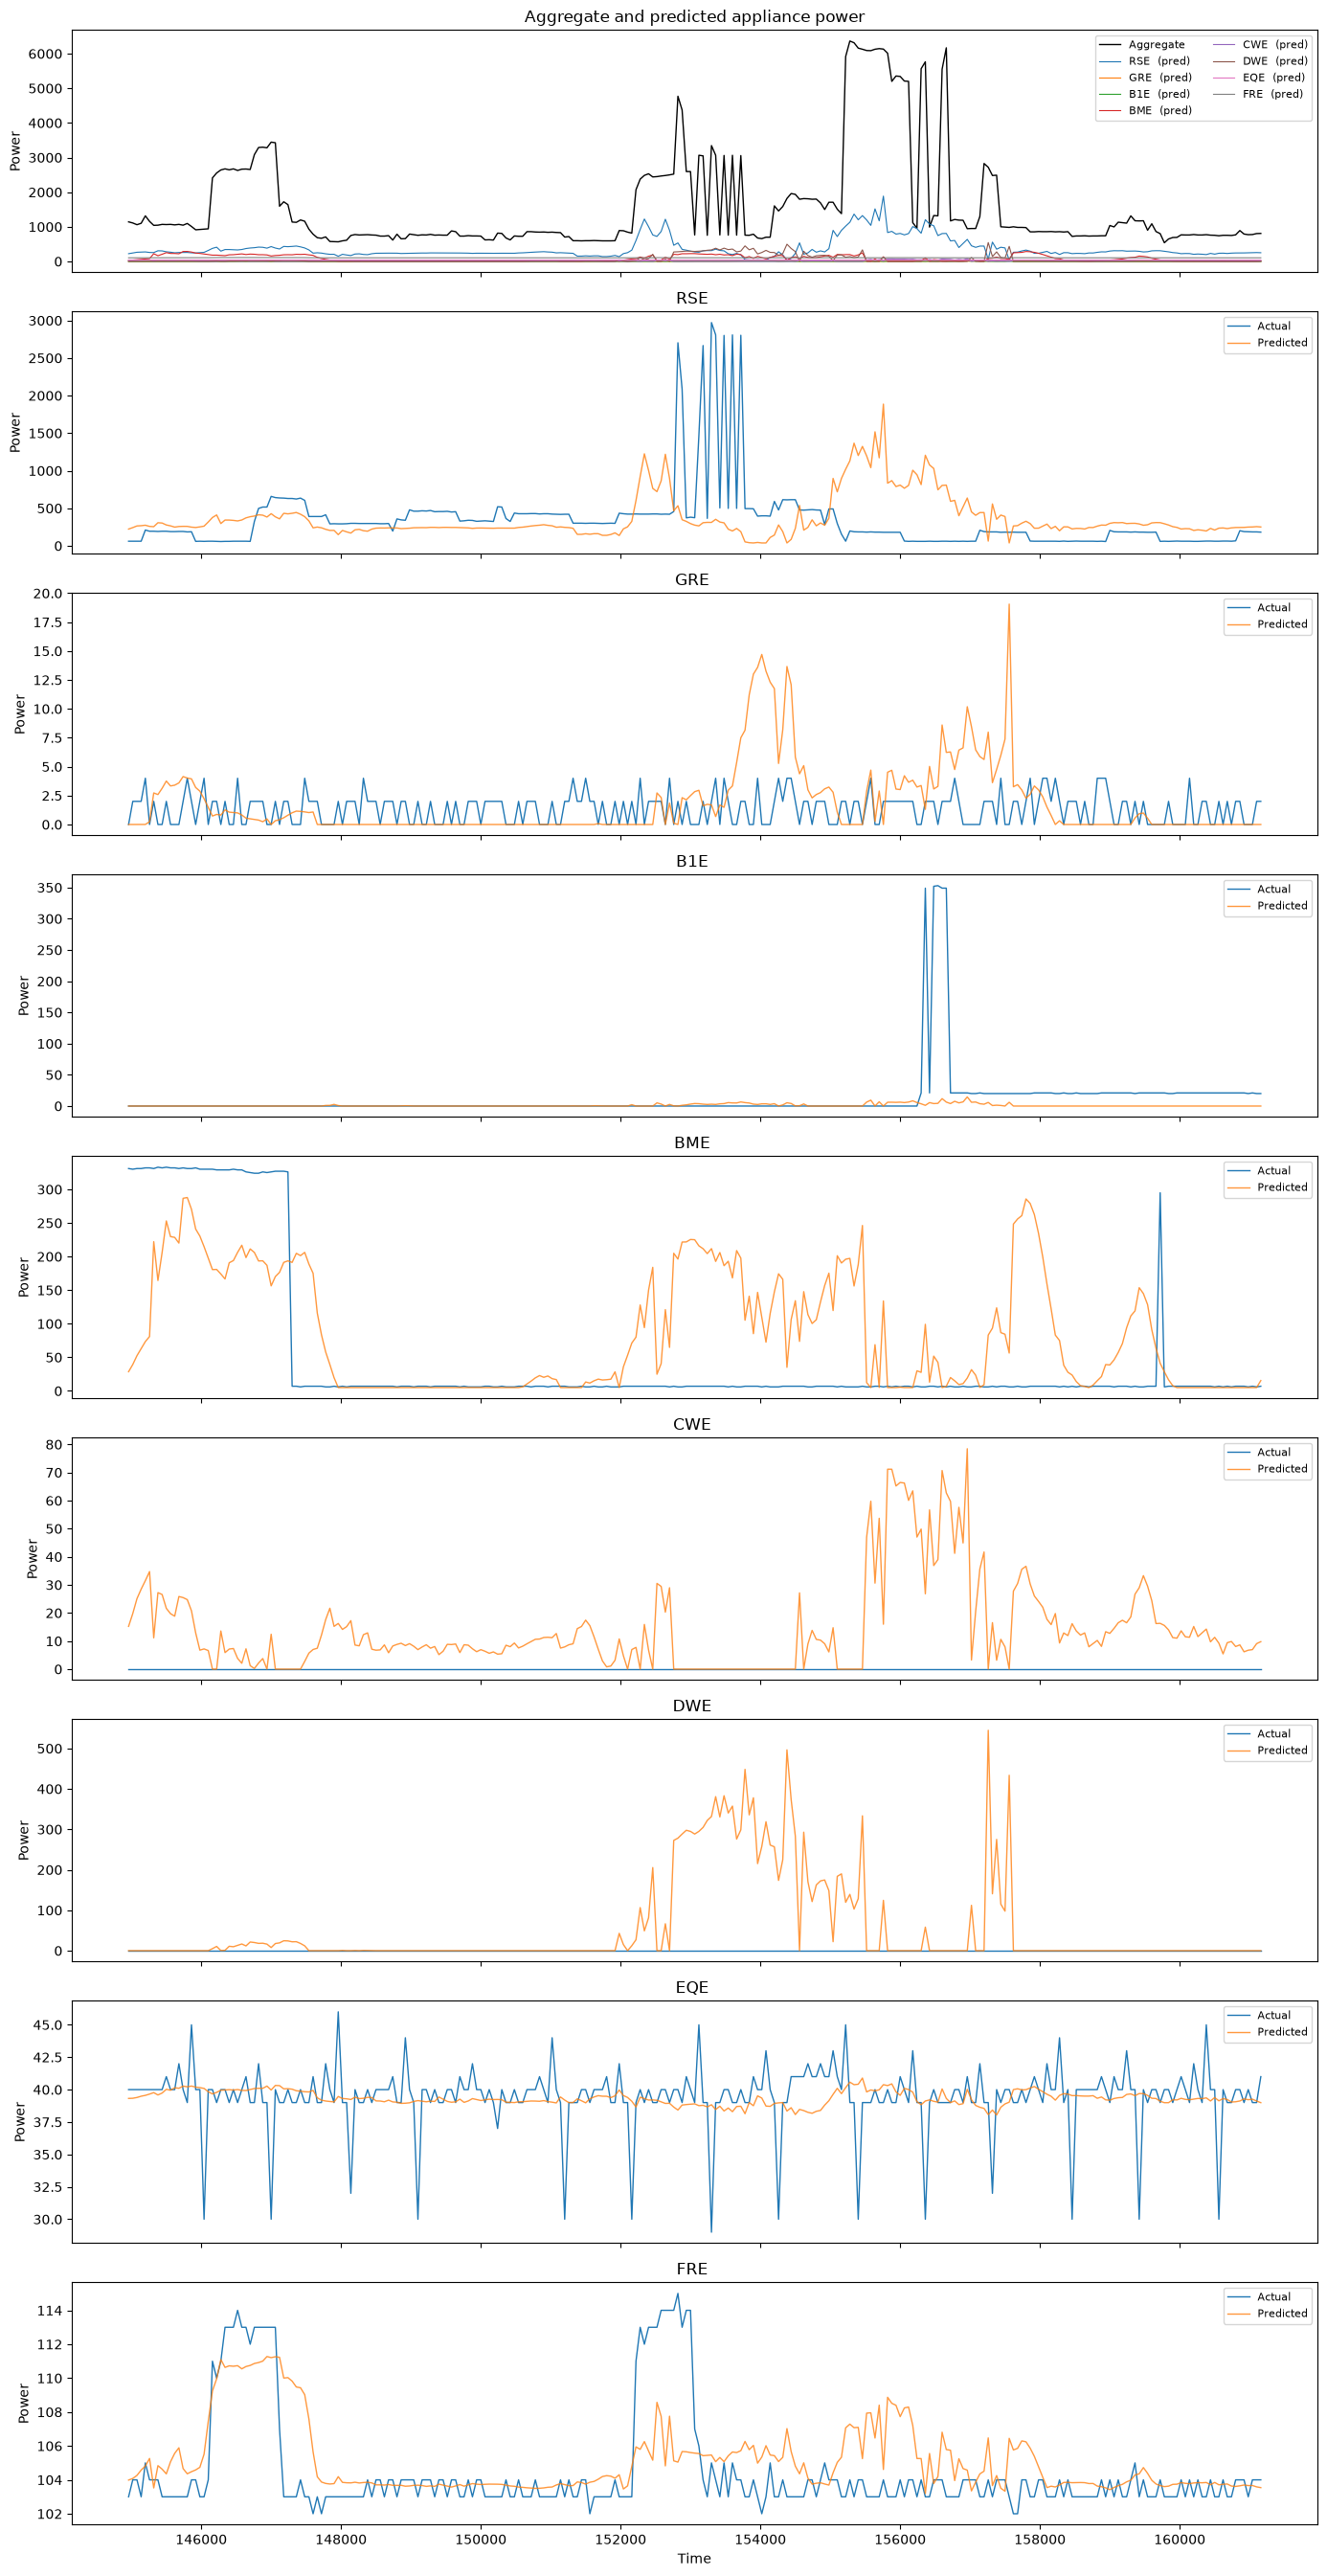

In [34]:
# Trim p_agg to remove timestamps that aren't present in the prediction.
p_agg_full = np.column_stack([time_id, p_agg])
p_agg_trimmed = p_agg_full[np.isin(p_agg_full[:, 0], apps_pred_full[:, 0])]

agg_df = pd.DataFrame(p_agg_trimmed, columns=['time', 'id', 'P'])
apps_df = pd.DataFrame(apps_pred_full, columns=apps_column_names)
apps_true_df = pd.DataFrame(p_apps_true, columns=apps_column_names)

t = agg_df.iloc[:, 0].values
app_names = apps_column_names[2:]  # appliance columns (matches the [:, 2:] slicing used for eacc)
n_apps = len(app_names)

fig, axes = plt.subplots(n_apps + 1, 1, figsize=(14, 3 * (n_apps + 1)), sharex=True)

# Top: aggregate power plus all predicted appliance traces
ax = axes[0]
ax.plot(t, agg_df.iloc[:, -1], color='k', lw=1, label='Aggregate')
for name in app_names:
    ax.plot(t, apps_df[name], lw=0.8, label=f'{name} (pred)')
ax.set_title('Aggregate and predicted appliance power')
ax.set_ylabel('Power')
ax.legend(loc='upper right', fontsize=8, ncol=2)

# One subplot per appliance: actual vs predicted
for ax, name in zip(axes[1:], app_names):
    ax.plot(t, apps_true_df[name], lw=1, label='Actual')
    ax.plot(t, apps_df[name], lw=1, alpha=0.8, label='Predicted')
    ax.set_title(name)
    ax.set_ylabel('Power')
    ax.legend(loc='upper right', fontsize=8)

axes[-1].set_xlabel('Time')
plt.tight_layout()
plt.show()


In [15]:
# Trim p_agg to remove timestamps that aren't present in the prediction.
p_agg_trimmed = p_agg.loc[p_agg.index.isin(apps_pred_full.index)]

agg_df = pd.DataFrame(p_agg, columns=agg_column_names)
apps_df = pd.DataFrame(apps_pred_full, columns=apps_column_names)

# Plot a separate time series for each appliance showing actual versus predicted power
# Plot aggregate power time series and all appliance time series together at the top
# put all plots in one figure

ValueError: Shape of passed values is (3000, 1), indices imply (3000, 6)